# Part 7: do the engineered features help the four models?

Question: if we cap the inputs at 10 columns, is a set built from **cluster averages + moving-average features + IC blend** better than the original 20 factors or an ANOVA-10 pick?

**Protocol (fixed before looking at results)**
- Inputs: `0_7_Feature_Engineering/mlfactor_fe_train.csv` / `_test.csv` from notebook 01.
- Target: does the stock beat the **median stock of its month** next month (balanced, removes market direction).
- Four model types: logistic regression, Gaussian naive Bayes, random forest, histogram gradient boosting. Three have tunable hyperparameters (small grids).
- Tuning: `GridSearchCV` on **train only**, with chronological expanding folds that keep each month together, scored by ROC-AUC.
- Strategy: every month hold the **top 20% by predicted probability**, equal weighted, long-only. Benchmark: equal-weighted market.
- Every feature set is fit and scored on the **same rows** (complete cases), so differences come from the features only.
- Models are frozen after fitting on train and applied once to test. The test period was already viewed in this project, so treat results as a sanity check, not clean out-of-sample evidence.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160, "display.max_columns", 40)

HERE = Path.cwd()
ROOT = HERE if (HERE / "mlfactor_long_only_train.csv").exists() else HERE.parent
FE = ROOT / "0_7_Feature_Engineering"
sys.path.insert(0, str(ROOT / "part0_data_and_benchmark"))
from pipeline import FEATURES, TARGET, return_month, performance    # shared course helpers

train = pd.read_csv(FE / "mlfactor_fe_train.csv", parse_dates=["date"])
test  = pd.read_csv(FE / "mlfactor_fe_test.csv",  parse_dates=["date"])

# Complete cases only: the first 12 train months lack long moving-average history.
# Using the same rows for every feature set keeps the comparison fair.
ALL_COLS = [c for c in train.columns if c not in ("date","stock_id",TARGET,"fwd_log_ret")]
train = train.dropna(subset=ALL_COLS).reset_index(drop=True)
test  = test.dropna(subset=ALL_COLS).reset_index(drop=True)

# Label: beats the cross-sectional median log return of its month
for d in (train, test):
    d["y"] = (d["fwd_log_ret"] > d.groupby("date")["fwd_log_ret"].transform("median")).astype(int)
print("train", train.shape, train.date.min().date(), "->", train.date.max().date(), "| base rate", train.y.mean().round(3))
print("test ", test.shape,  test.date.min().date(),  "->", test.date.max().date(),  "| base rate", test.y.mean().round(3))

train (126066, 68) 2000-12-31 -> 2009-11-30 | base rate 0.497
test  (127620, 68) 2009-12-31 -> 2018-11-30 | base rate 0.497


## 1. The four feature sets (all <= 10 columns, chosen from train only)

| Set | Columns | Idea |
|---|---|---|
| `raw20` | the 20 original factors | reference |
| `anova10` | top 10 by ANOVA F-test vs the label | simple supervised pick |
| `clusters9` | the 9 cluster averages | unsupervised: same information, redundancy removed |
| `engineered10` | 6 cluster averages + the IC blend + 3 moving-average ranks | adds the price-history information |

For `engineered10` the 3 moving-average ranks are picked greedily by train |ICIR| while skipping any with correlation above 0.6 with one already picked.

In [2]:
def monthly_ic(df, cols, target="fwd_log_ret"):
    """Spearman IC per month (rank corr of feature with future log return)."""
    yr = df.groupby("date")[target].rank(pct=True)
    return pd.DataFrame({c: df.groupby("date")[c].rank(pct=True).groupby(df["date"]).corr(yr) for c in cols})

# --- anova10: fit the selector on train only ---
anova = SelectKBest(f_classif, k=10).fit(train[FEATURES], train.y)
ANOVA10 = list(np.array(FEATURES)[anova.get_support()])

# --- clusters9: all cluster averages from notebook 01 ---
CL_ALL = [c for c in train.columns if c.startswith("cl") and c.endswith("_avg")]

# --- engineered10: 6 cluster avgs (largest groups first) + IC blend + 3 decorrelated technical ranks ---
TA_RK = [c for c in train.columns if c.startswith("ta_") and c.endswith("_rk")]
ic_ta = monthly_ic(train, TA_RK)
order = (ic_ta.mean() / ic_ta.std()).abs().sort_values(ascending=False).index
corr_ta = train[TA_RK].corr(method="spearman")
TA3 = []
for f in order:
    if all(abs(corr_ta.loc[f, c]) < 0.6 for c in TA3): TA3.append(f)
    if len(TA3) == 3: break
CL6 = ["cl5_avg","cl1_avg","cl2_avg","cl4_avg","cl6_avg","cl3_avg"]   # multi-member groups + Div_Yld
ENG10 = CL6 + ["blend_ic_pruned"] + TA3

SETS = {"raw20": FEATURES, "anova10": ANOVA10, "clusters9": CL_ALL, "engineered10": ENG10}
for k, v in SETS.items(): print(f"{k:13s} ({len(v):2d}):", v)

raw20         (20): ['Ocf_Toa', 'Tot_Debt_Rev', 'Net_Debt', 'Total_Liabilities_Total_Assets', 'Share_Turn_3M', 'Fcf_Tbv', 'Debtequity', 'Ocf_Ce', 'Fcf_Yld', 'Ocf_Tbv', 'Div_Yld', 'Netdebtyield', 'Share_Turn_12M', 'Tev_Less_Mktcap', 'Bb_Yld', 'Ev_Ebitda', 'Total_Debt_Capital', 'Share_Turn_6M', 'Capex_Sales', 'Ocf_Ta']
anova10       (10): ['Ocf_Toa', 'Tot_Debt_Rev', 'Net_Debt', 'Total_Liabilities_Total_Assets', 'Ocf_Ce', 'Fcf_Yld', 'Ocf_Tbv', 'Div_Yld', 'Ev_Ebitda', 'Ocf_Ta']
clusters9     ( 9): ['cl5_avg', 'cl1_avg', 'cl2_avg', 'cl4_avg', 'cl6_avg', 'cl3_avg', 'cl8_avg', 'cl9_avg', 'cl7_avg']
engineered10  (10): ['cl5_avg', 'cl1_avg', 'cl2_avg', 'cl4_avg', 'cl6_avg', 'cl3_avg', 'blend_ic_pruned', 'ta_px_vs_ma_3m_rk', 'ta_px_vs_ma_12m_rk', 'ta_vol_6m_rk']


## 2. Models, grids, and chronological tuning folds

`GridSearchCV` receives explicit train/validation index pairs: each fold trains on all earlier months and validates on the next block of months, so no validation month ever precedes a training month. Hyperparameters are chosen by validation ROC-AUC. A sixth-of-the-sample first fold keeps enough history.

In [3]:
MODELS = {
    "logistic": (LogisticRegression(max_iter=500), {"C": [0.01, 0.1, 1, 10]}),
    "naive_bayes": (GaussianNB(), {"var_smoothing": [1e-9, 1e-6, 1e-3]}),
    "random_forest": (RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=0),
                      {"max_depth": [3, 6], "min_samples_leaf": [200, 1000]}),
    "grad_boosting": (HistGradientBoostingClassifier(max_iter=150, random_state=0),
                      {"max_depth": [2, 3], "learning_rate": [0.03, 0.1]}),
}

def month_splits(df, n_folds=5):
    """Expanding-window folds by calendar month; months are never split across train/validation."""
    months = np.sort(df["date"].unique())
    edges = np.linspace(len(months) // 6, len(months), n_folds + 1).astype(int)   # first train block = 1/6 of history
    out = []
    for a, b in zip(edges[:-1], edges[1:]):
        tr = np.where(df["date"].isin(months[:a]))[0]
        va = np.where(df["date"].isin(months[a:b]))[0]
        out.append((tr, va))
    return out
SPLITS = month_splits(train)
print("folds (train months -> validation months):",
      [(len(np.unique(train.date.iloc[a])), len(np.unique(train.date.iloc[b]))) for a, b in SPLITS])

# Equal-weight benchmark and top-quintile strategy return builders
TOP_FRAC = 0.20
def to_series(g):
    s = g.copy(); s.index = return_month(s.index); return s     # snapshot month -> month the return is earned

def ew_returns(df):
    return to_series(df.groupby("date")[TARGET].mean())

def top_returns(df, score):
    pct = score.groupby(df["date"]).rank(pct=True, method="first")
    return to_series(df[pct > 1 - TOP_FRAC].groupby("date")[TARGET].mean())

def mean_ic(df, score):
    return df.assign(s=score).pipe(lambda d: monthly_ic(d, ["s"], "fwd_log_ret")["s"]).mean()

folds (train months -> validation months): [(18, 18), (36, 18), (54, 18), (72, 18), (90, 18)]


In [4]:
rows, test_scores, best_params = [], {}, {}
for set_name, cols in SETS.items():
    for m_name, (est, grid) in MODELS.items():
        # --- tuned: GridSearchCV on train only ---
        gs = GridSearchCV(clone(est), grid, cv=SPLITS, scoring="roc_auc", n_jobs=1, refit=True)
        gs.fit(train[cols], train.y)
        # --- default hyperparameters, to measure whether tuning helps ---
        default = clone(est).fit(train[cols], train.y)
        for tag, model in (("tuned", gs.best_estimator_), ("default", default)):
            p = pd.Series(model.predict_proba(test[cols])[:, 1], index=test.index)
            test_scores[(set_name, m_name, tag)] = p
            r = top_returns(test, p)
            perf = performance(r)
            rows.append({"set": set_name, "model": m_name, "tuning": tag,
                         "cv_auc": gs.best_score_ if tag == "tuned" else np.nan,
                         "test_auc": roc_auc_score(test.y, p), "test_IC": mean_ic(test, p),
                         "cagr": perf.cagr, "vol": perf.annualized_volatility, "sharpe": perf.sharpe,
                         "max_dd": perf.max_drawdown})
        best_params[(set_name, m_name)] = gs.best_params_
        print(f"done {set_name:13s} {m_name:14s} cv_auc={gs.best_score_:.4f} best={gs.best_params_}")

res = pd.DataFrame(rows)
bench = performance(ew_returns(test))
print("\nEqual-weight market (test): CAGR %.2f%%  vol %.2f%%  Sharpe %.2f  maxDD %.1f%%" %
      (bench.cagr*100, bench.annualized_volatility*100, bench.sharpe, bench.max_drawdown*100))

done raw20         logistic       cv_auc=0.5006 best={'C': 10}
done raw20         naive_bayes    cv_auc=0.4991 best={'var_smoothing': 1e-06}
done raw20         random_forest  cv_auc=0.5136 best={'max_depth': 6, 'min_samples_leaf': 200}
done raw20         grad_boosting  cv_auc=0.5120 best={'learning_rate': 0.03, 'max_depth': 3}
done anova10       logistic       cv_auc=0.4939 best={'C': 10}
done anova10       naive_bayes    cv_auc=0.5041 best={'var_smoothing': 1e-09}
done anova10       random_forest  cv_auc=0.5146 best={'max_depth': 6, 'min_samples_leaf': 200}
done anova10       grad_boosting  cv_auc=0.5137 best={'learning_rate': 0.1, 'max_depth': 3}
done clusters9     logistic       cv_auc=0.4921 best={'C': 10}
done clusters9     naive_bayes    cv_auc=0.4990 best={'var_smoothing': 1e-09}
done clusters9     random_forest  cv_auc=0.5110 best={'max_depth': 6, 'min_samples_leaf': 200}
done clusters9     grad_boosting  cv_auc=0.5103 best={'learning_rate': 0.1, 'max_depth': 2}
done engineered

## 3. Results
Tuned models only first, then the effect of tuning.

In [5]:
tuned = res[res.tuning == "tuned"]
for metric, fmt in (("cv_auc", "{:.4f}"), ("test_auc", "{:.4f}"), ("test_IC", "{:.4f}"), ("cagr", "{:.2%}"), ("sharpe", "{:.2f}"), ("max_dd", "{:.1%}")):
    t = tuned.pivot(index="model", columns="set", values=metric)[list(SETS)]
    print(f"--- {metric} (tuned) ---"); print(t.map(fmt.format).to_string()); print()
print(f"Equal-weight market: CAGR {bench.cagr:.2%}, Sharpe {bench.sharpe:.2f}, max drawdown {bench.max_drawdown:.1%}")

--- cv_auc (tuned) ---
set             raw20 anova10 clusters9 engineered10
model                                               
grad_boosting  0.5120  0.5137    0.5103       0.5122
logistic       0.5006  0.4939    0.4921       0.5032
naive_bayes    0.4991  0.5041    0.4990       0.5048
random_forest  0.5136  0.5146    0.5110       0.5109

--- test_auc (tuned) ---
set             raw20 anova10 clusters9 engineered10
model                                               
grad_boosting  0.4986  0.4975    0.4999       0.5026
logistic       0.5021  0.5011    0.5047       0.5015
naive_bayes    0.5042  0.5025    0.5039       0.5020
random_forest  0.5012  0.4983    0.4994       0.5039

--- test_IC (tuned) ---
set              raw20  anova10 clusters9 engineered10
model                                                 
grad_boosting  -0.0061  -0.0072   -0.0013       0.0086
logistic        0.0029   0.0039    0.0083       0.0042
naive_bayes     0.0052   0.0028    0.0051       0.0042
random_forest  

In [6]:
# Does tuning to ROC-AUC help the strategy? (test CAGR / Sharpe, tuned minus default)
wide = res.pivot_table(index=["set","model"], columns="tuning", values=["cagr","sharpe","test_auc"])
delta = pd.DataFrame({"d_cagr": wide["cagr"]["tuned"] - wide["cagr"]["default"],
                      "d_sharpe": wide["sharpe"]["tuned"] - wide["sharpe"]["default"],
                      "d_test_auc": wide["test_auc"]["tuned"] - wide["test_auc"]["default"]})
print(delta.round(4).to_string())
print("\nmean change from tuning:", delta.mean().round(4).to_dict())
print("share of cases where tuning improved Sharpe:", (delta.d_sharpe > 0).mean().round(2))

                            d_cagr  d_sharpe  d_test_auc
set          model                                      
anova10      grad_boosting  0.0028   -0.0003     -0.0019
             logistic      -0.0004   -0.0020     -0.0000
             naive_bayes    0.0000    0.0000      0.0000
             random_forest -0.0174   -0.1022      0.0004
clusters9    grad_boosting  0.0037    0.0032      0.0001
             logistic      -0.0000    0.0001      0.0000
             naive_bayes    0.0000    0.0000      0.0000
             random_forest -0.0025   -0.0277     -0.0005
engineered10 grad_boosting  0.0107    0.0121      0.0006
             logistic       0.0006    0.0032      0.0000
             naive_bayes    0.0000    0.0000      0.0000
             random_forest  0.0385    0.1433     -0.0013
raw20        grad_boosting -0.0138   -0.0396     -0.0014
             logistic       0.0015    0.0129     -0.0001
             naive_bayes    0.0000    0.0000     -0.0000
             random_forest  0.0

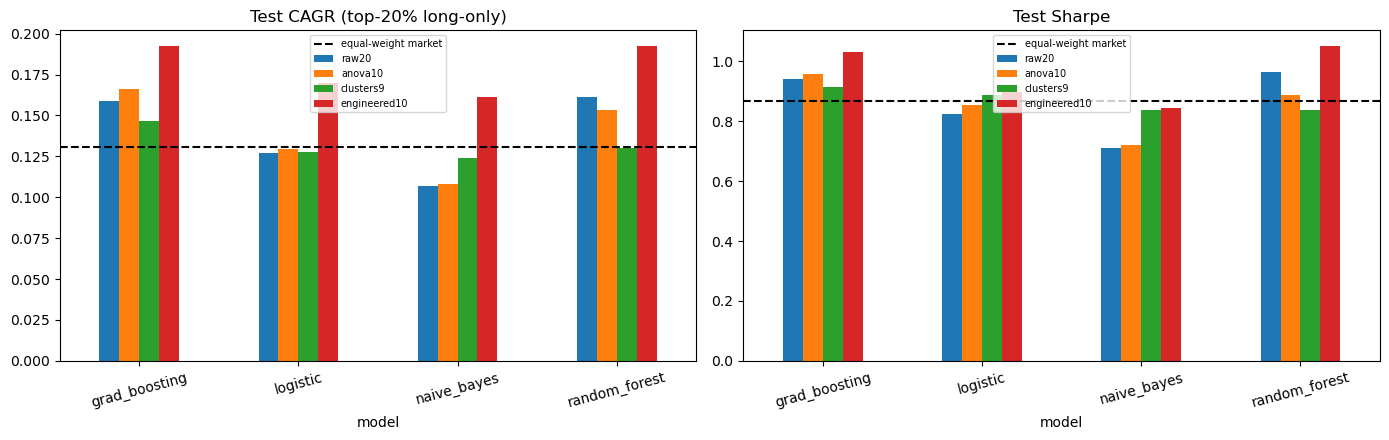

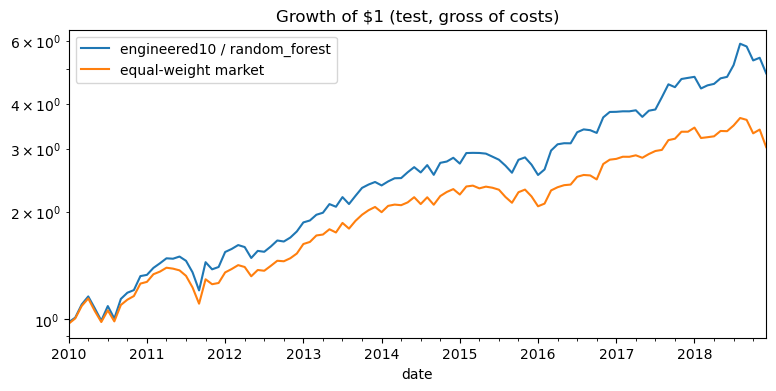

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, metric, title in zip(ax, ("cagr", "sharpe"), ("Test CAGR (top-20% long-only)", "Test Sharpe")):
    t = tuned.pivot(index="model", columns="set", values=metric)[list(SETS)]
    t.plot(kind="bar", ax=a, rot=15)
    a.axhline(bench.cagr if metric == "cagr" else bench.sharpe, c="k", ls="--", label="equal-weight market")
    a.set_title(title); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

# Cumulative growth of the best tuned engineered10 model vs the market
best = tuned[tuned.set == "engineered10"].sort_values("sharpe").iloc[-1]
p = test_scores[("engineered10", best.model, "tuned")]
growth = pd.DataFrame({f"engineered10 / {best.model}": (1 + top_returns(test, p)).cumprod(),
                       "equal-weight market": (1 + ew_returns(test)).cumprod()})
growth.plot(figsize=(9, 4), logy=True, title="Growth of $1 (test, gross of costs)"); plt.show()

In [8]:
# Persist the full grid so the write-up does not need a re-run.
res.to_csv(FE / "part7_model_comparison.csv", index=False)
pd.Series({f"{k[0]}|{k[1]}": v for k, v in best_params.items()}).to_json(FE / "part7_best_params.json", indent=2)
print("saved part7_model_comparison.csv and part7_best_params.json")

saved part7_model_comparison.csv and part7_best_params.json


## 4. Where does the engineered10 advantage come from?

The engineered set has the best CAGR for every model, yet every ROC-AUC is about 0.50, so the models barely rank stocks better than chance. Check what the top-20% portfolios actually hold, and compare with a trivial rule that needs no model: buy the top quintile by 6-month volatility rank.

In [9]:

# Exposure check for the tuned random forest on engineered10 vs raw20 (test period)
def picks(model_set, model):
    p = test_scores[(model_set, model, "tuned")]
    pct = p.groupby(test["date"]).rank(pct=True, method="first")
    return test[pct > 1 - TOP_FRAC]

exp = pd.DataFrame({s: picks(s, "random_forest")[["ta_vol_6m_rk", "ta_ret_1m_rk"]].mean() for s in ("raw20", "engineered10")})
exp.index = ["avg 6M-volatility rank of holdings", "avg last-month-return rank of holdings"]
print(exp.round(3).to_string(), "\n(0.5 = same as the market)")

# Model-free comparator: top quintile by volatility rank alone
vol_only = performance(top_returns(test, test["ta_vol_6m_rk"]))
print(f"\nTop quintile by 6M volatility alone: CAGR {vol_only.cagr:.2%}, Sharpe {vol_only.sharpe:.2f}, max drawdown {vol_only.max_drawdown:.1%}")
print(f"Equal-weight market:                  CAGR {bench.cagr:.2%}, Sharpe {bench.sharpe:.2f}, max drawdown {bench.max_drawdown:.1%}")

# Paired monthly difference: engineered10 RF minus raw20 RF (t-stat on 108 monthly differences)
d = top_returns(test, test_scores[("engineered10", "random_forest", "tuned")]) - top_returns(test, test_scores[("raw20", "random_forest", "tuned")])
print(f"\nengineered10 - raw20 (RF): mean {d.mean():.4f}/month, t = {d.mean() / d.std() * np.sqrt(len(d)):.2f}")


                                        raw20  engineered10
avg 6M-volatility rank of holdings      0.530           0.6
avg last-month-return rank of holdings  0.469           0.3 
(0.5 = same as the market)

Top quintile by 6M volatility alone: CAGR 18.40%, Sharpe 0.84, max drawdown -27.0%
Equal-weight market:                  CAGR 13.10%, Sharpe 0.87, max drawdown -20.7%

engineered10 - raw20 (RF): mean 0.0024/month, t = 2.00


## 5. Takeaways

1. **Predictive power is essentially nil everywhere.** Tuned cross-validated AUCs are 0.49-0.515 and test AUCs 0.497-0.505 for all 16 set/model combinations. The engineered features do not change that.
2. **Fewer columns lose nothing.** `clusters9` (unsupervised, 9 columns) scores about the same as `raw20` on CV AUC, so the redundancy removal costs no signal. That supports using cluster averages as the way to meet the 10-feature limit.
3. **`engineered10` earns the best CAGR and Sharpe for all four models** (CAGR 16-19% against 13.1% for the equal-weight market). But the holdings tilt toward high-volatility stocks, and a model-free top-volatility quintile earns a similar CAGR. Treat the gain as a volatility/reversal tilt, not as the models learning something new. It also carries slightly deeper drawdowns for three of the four models.
4. **Tuning to ROC-AUC barely matters for the strategy.** The average change in test Sharpe is about +0.004, and tuning improved Sharpe in fewer than half of the cases. Naive Bayes is unchanged because its grid did not alter predictions. AUC is a ranking metric over all stocks, while the strategy only uses the top 20%, so a small mismatch is expected.
5. **Caveats.** The test period was already viewed in this project, results are gross of transaction costs, and the 108 test months are one market path. Do not present these as clean out-of-sample evidence.

**What to try next:** make the volatility tilt explicit, in line with the project's existing top-volatility baskets, and then test whether any model adds value *beyond* that tilt, for example by ranking stocks only within volatility buckets.